# Effectiveness of thrombolysis in early (4hr) arrivals of mild stroke, by individual NIHSS (1, 2, 3, 4, 5) - good outcome: Target trial emulation

This notebook estimates the effect of thrombolysis on good outcome in mild stroke (NIHSS 1–5), **separately for each NIHSS score**, and for three onset-to-thrombolysis windows.

**Good outcome = discharge mRS 0–2, or discharge mRS no worse than pre-stroke mRS**

### The target trial being emulated

| Protocol component | Target trial | How it is emulated with SSNAP data |
|---|---|---|
| **Eligibility** | Ischaemic stroke, NIHSS 1–5, arriving within 4 hours of known onset, not having thrombectomy | Infarction; onset-to-arrival < 240 min; NIHSS 1–5; no thrombectomy; no perfusion imaging; discharge mRS recorded; stroke team gave at least 10 thrombolyses in the cohort |
| **Treatment strategies** | Thrombolysis within < 180, 180–270 or 270–360 min of onset, vs no thrombolysis | Strategy assigned from recorded onset-to-thrombolysis time |
| **Assignment** | Random | Not random. Each thrombolysed patient is exactly matched to an untreated patient with the same pre-stroke mRS, NIHSS, age, AF anticoagulant use and AF diagnosis |
| **Outcome** | Good outcome at discharge | As target trial |
| **Causal contrast** | Effect of thrombolysis in those treated | Difference between matched thrombolysed and untreated patients |
| **Analysis** | Paired difference in proportions with 95% CI; McNemar's test | As target trial, by NIHSS and time window; sensitivity analyses at the end |

### Notebook structure

1. Settings
2. Cohort selection and treatment groups
3. Matching
4. Analysis by NIHSS and time window: summary table, headline table, chart
5. Balance of patient characteristics after matching
6. Sensitivity analyses
7. Conclusions and limitations

### Key findings

* **No detectable benefit at NIHSS 1 or 2.** Good-outcome differences are −0.3 and +0.9 percentage points, with CIs including zero. About 83–85% of matched controls already have a good outcome.
* **Benefit from NIHSS 3 upwards, growing with severity:** +4.8 points at NIHSS 3, +6.6 at NIHSS 4 and +8.5 at NIHSS 5. All CIs exclude zero.
* **Earlier is better:** pooled over NIHSS 1–5, +6.8 points within 180 min, +4.6 at 180–270 min, and +2.1 at 270–360 min (CI includes zero; only 475 pairs).

* **Robust to the sensitivity analyses:**
  * the NIHSS 3–5 benefit holds in every analysis (all CIs exclude zero)
  * NIHSS 1 shows no benefit in any analysis
  * NIHSS 2 shows a small, uncertain difference (−0.5 to +3.4 points across random seeds)
* **Vulnerable to unmeasured confounding:** E-values are modest (1.3–1.5), so unmeasured confounding of moderate strength could explain the results.

## Load modules

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings("ignore")

## Settings

All analysis choices are set here. The sensitivity analyses later change one of these at a time.

In [2]:
prefix = "mild_stroke_by_nihss_1_to_5_early_arrival_good_outcome_target_trial"
DATA_PATH = "../data/sam3/cleaned_data_anon_teams.csv"
OUTPUT_DIR = "./output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Outcome
MRS_TARGET = 2                 # good outcome: discharge mRS <= MRS_TARGET, or no worse than pre-stroke mRS

# Cohort
NIHSS_VALUES = [1, 2, 3, 4, 5]
MAX_ARRIVAL = 240              # include patients arriving within this many minutes of onset
MAX_THROMBOLYSIS = 360         # exclude thrombolysis later than this
MIN_TEAM_THROMBOLYSIS = 10     # include teams that gave at least this many thrombolyses in the cohort

# Treatment groups: upper limits (minutes) of the onset-to-thrombolysis windows
TIME_WINDOWS = [180, 270, 360]
CONTROL_GROUP = "No thrombolysis"
ALL_TREATED = "All (≤360 min)"

# Matching
MATCHING_FEATURES = [
    'prior_disability',
    'stroke_severity',
    'age',
    'afib_anticoagulant',
    'any_afib_diagnosis',
]
MAX_CONTROL_USES = 3           # k: maximum times an untreated patient can be a control (None = unlimited)
MATCH_SEED = 42                # base random seed for picking a control

# Baseline features used to check balance after matching
COMORBIDITIES = ['congestive_heart_failure', 'hypertension', 'diabetes']
BASELINE_FEATURES = MATCHING_FEATURES + COMORBIDITIES

NO_TREATMENT = 99999           # sentinel time meaning "not thrombolysed"
TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"

## Cohort selection and treatment groups

### Eligibility

Patients are included if they:

* had an ischaemic stroke (infarction) and a recorded discharge mRS
* arrived within 4 hours (240 minutes) of known stroke onset, so all had time to be assessed for thrombolysis
* did not have perfusion imaging or thrombectomy, so the comparison is thrombolysis versus no thrombolysis only. In this dataset, every patient with perfusion imaging also had thrombectomy, so the perfusion-imaging criterion removes no extra patients.
* had NIHSS 1–5 (mild stroke)
* were treated by a stroke team that gave at least 10 thrombolyses in this cohort

Thrombolysis more than 360 minutes after onset is excluded as implausible.

### Treatment groups

Thrombolysed patients are grouped by onset-to-thrombolysis time: **< 180 min** (≤ 180), **180–270 min** and **270–360 min**. Patients not thrombolysed are the control pool.

In [3]:
def good_outcome(df, mrs_target=MRS_TARGET, allow_no_worse_than_prior=True):
    # 1 if discharge mRS <= mrs_target, or (optionally) discharge mRS no worse than pre-stroke mRS
    outcome = df["discharge_disability"] <= mrs_target
    if allow_no_worse_than_prior:
        outcome = outcome | (df["discharge_disability"] <= df["prior_disability"])
    return outcome.astype(int)


def time_group_labels(windows=TIME_WINDOWS):
    # e.g. [180, 270, 360] -> ["<180 min", "180-270 min", "270-360 min"]
    return [f"<{windows[0]} min"] + [f"{a}-{b} min" for a, b in zip(windows[:-1], windows[1:])]


def assign_time_groups(df, windows=TIME_WINDOWS):
    # Onset-to-thrombolysis window; untreated patients (sentinel time) are the control group
    time = df[TIME_THROMBOLYSIS]
    group = pd.Series(CONTROL_GROUP, index=df.index, dtype=object)
    lower = -np.inf
    for label, upper in zip(time_group_labels(windows), windows):
        group[(time > lower) & (time <= upper)] = label
        lower = upper
    df["treatment_group"] = group
    return df


def build_cohort(raw, max_arrival=MAX_ARRIVAL, min_team_thrombolysis=MIN_TEAM_THROMBOLYSIS,
                 exclude_perfusion_imaging=True, verbose=False):
    # Apply eligibility criteria and add outcome, treatment group and patient id.
    # Arguments allow the sensitivity analyses to change one choice at a time.
    df = raw
    log = [("All records", len(df))]

    def keep_rows(label, mask):
        nonlocal df
        df = df[mask]
        log.append((label, len(df)))

    keep_rows("Discharge mRS recorded", df["discharge_disability"].notna())
    keep_rows("Infarction", df["infarction"] == 1)
    keep_rows(f"Arrival within {max_arrival} min of onset", df["onset_to_arrival_time"] < max_arrival)
    if exclude_perfusion_imaging:
        keep_rows("No perfusion imaging", df["perfusion_imaging_used"] == 0)
    keep_rows("No thrombectomy", df["thrombectomy"] == 0)
    keep_rows("NIHSS 1-5", df["stroke_severity"].between(1, 5))

    team_counts = df.groupby("stroke_team")[TIME_THROMBOLYSIS].count()
    eligible_teams = team_counts.index[team_counts >= min_team_thrombolysis]
    keep_rows(f"Team gave >= {min_team_thrombolysis} thrombolyses", df["stroke_team"].isin(eligible_teams))

    df = df.copy()
    df[TIME_THROMBOLYSIS] = df[TIME_THROMBOLYSIS].fillna(NO_TREATMENT)  # missing time = not thrombolysed
    keep_rows(f"Thrombolysis (if given) <= {MAX_THROMBOLYSIS} min",
              (df[TIME_THROMBOLYSIS] <= MAX_THROMBOLYSIS) | (df[TIME_THROMBOLYSIS] == NO_TREATMENT))

    df = df.copy()
    df["outcome_target"] = good_outcome(df)
    df = assign_time_groups(df)
    df["patient_id"] = np.arange(len(df))

    if verbose:
        display(pd.DataFrame(log, columns=["Step", "Patients remaining"]))
    return df


raw_data = pd.read_csv(DATA_PATH, low_memory=False)
data = build_cohort(raw_data, verbose=True)

,Step,Patients remaining
0,All records,452863
1,Discharge mRS recorded,438589
2,Infarction,384365
3,Arrival within 240 min of onset,135944
4,No perfusion imaging,133895
5,No thrombectomy,125703
6,NIHSS 1-5,58514
7,Team gave >= 10 thrombolyses,58458
8,Thrombolysis (if given) <= 360 min,58389


In [4]:
# Patients available before matching, by NIHSS and treatment group
pd.crosstab(data["stroke_severity"], data["treatment_group"], margins=True)

treatment_group,180-270 min,270-360 min,<180 min,No thrombolysis,All
stroke_severity,,,,,
1.0,341,34,347,10280,11002
2.0,732,90,925,12398,14145
3.0,1162,98,1525,10071,12856
4.0,1601,131,2220,7016,10968
5.0,1678,123,2373,5244,9418
All,5514,476,7390,45009,58389


**What this shows:** 58,389 patients are eligible and 13,380 (23%) were thrombolysed. The proportion thrombolysed rises steeply with NIHSS: about 7% at NIHSS 1 and 44% at NIHSS 5. Most thrombolysis is given within 270 minutes; only 476 patients were treated at 270–360 minutes.

## Matching

Each thrombolysed patient is matched to one untreated patient. The method:

* **Exact matching** on all matching features. NIHSS is matched exactly, so every matched pair sits within a single NIHSS score, and results can be split by NIHSS without re-matching.
* **Random choice:** if several untreated patients match, one is picked at random (seed `MATCH_SEED + n` for the *n*-th treated patient in each group, so results are reproducible).
* **Limited reuse of controls:** each untreated patient can be a control at most *k* = `MAX_CONTROL_USES` (3) times. The limit is **shared across the three time windows**, so the order of matching matters. Groups are matched in the order 180–270, 270–360, then < 180 min (alphabetical order of the labels), with patients in data order within each group.
* **Unmatched patients:** a treated patient with no available match (no exact match, or all matching controls used *k* times) is dropped.

Untreated patients are pre-grouped by matching features, which gives identical matches to a row-by-row search but runs much faster.

In [5]:
def match_patients(df, matching_features=MATCHING_FEATURES, max_control_uses=MAX_CONTROL_USES,
                   base_seed=MATCH_SEED, group_order=None):
    # Exact 1:1 matching with a shared limit on control reuse.
    # Returns (matched, unmatched, control_use_count):
    #   matched[group] = {"treated": df, "untreated": df, "n_treated_total": int}, row i paired with row i
    #   unmatched = one row per treated patient left unmatched, with the reason
    matching_features = list(matching_features)
    untreated = df[df["treatment_group"] == CONTROL_GROUP]
    if group_order is None:
        group_order = sorted(g for g in df["treatment_group"].unique() if g != CONTROL_GROUP)

    # Row positions of untreated patients for each combination of matching features (data order kept)
    untreated_lookup = untreated.groupby(matching_features, sort=False).indices
    control_use_count = np.zeros(len(untreated), dtype=int)
    max_uses = np.inf if max_control_uses is None else max_control_uses

    matched, unmatched = {}, []
    for group_name in group_order:
        treated = df[df["treatment_group"] == group_name]
        if treated.empty:
            continue
        treated_positions, untreated_positions = [], []
        for count, key in enumerate(treated[matching_features].itertuples(index=False, name=None), start=1):
            candidates = untreated_lookup.get(key)
            if candidates is None or len(candidates) == 0:
                reason = "no exact match"
            else:
                available = candidates[control_use_count[candidates] < max_uses]
                if len(available) > 0:
                    chosen = pd.Series(available).sample(n=1, random_state=base_seed + count).iloc[0]
                    control_use_count[chosen] += 1
                    treated_positions.append(count - 1)
                    untreated_positions.append(chosen)
                    continue
                reason = f"all matching controls used {max_control_uses} times"
            unmatched.append({"treatment_group": group_name,
                              "stroke_severity": key[matching_features.index("stroke_severity")],
                              "reason": reason})

        matched[group_name] = {
            "treated": treated.iloc[treated_positions].reset_index(drop=True),
            "untreated": untreated.iloc[untreated_positions].reset_index(drop=True),
            "n_treated_total": len(treated),
        }
    return matched, pd.DataFrame(unmatched, columns=["treatment_group", "stroke_severity", "reason"]), control_use_count


def make_pairs(matched):
    # One row per matched pair, with what is needed to recompute outcomes in sensitivity analyses
    pairs = []
    for group_name, s in matched.items():
        t, u = s["treated"], s["untreated"]
        pairs.append(pd.DataFrame({
            "treatment_group": group_name,
            "stroke_severity": t["stroke_severity"].astype(int),
            "treated_outcome": t["outcome_target"].astype(int),
            "untreated_outcome": u["outcome_target"].astype(int),
            "treated_mrs": t["discharge_disability"],
            "untreated_mrs": u["discharge_disability"],
            "treated_prior_mrs": t["prior_disability"],
            "untreated_prior_mrs": u["prior_disability"],
            "control_id": u["patient_id"].to_numpy(),
        }))
    return pd.concat(pairs, ignore_index=True)


matched_samples, unmatched, control_use_count = match_patients(data)
pairs = make_pairs(matched_samples)
treated_all = data[data["treatment_group"] != CONTROL_GROUP]

# Matching summary
matching_summary = pd.DataFrame([
    {"treatment_group": g, "treated": s["n_treated_total"], "matched": len(s["treated"]),
     "percent_matched": round(100 * len(s["treated"]) / s["n_treated_total"], 2)}
    for g, s in matched_samples.items()
])
display(matching_summary)
display(unmatched.groupby(["treatment_group", "reason"]).size().rename("unmatched").to_frame())

used = control_use_count[control_use_count > 0]
print(f"Total matched pairs: {len(pairs)}")
print(f"Distinct controls used: {len(used)}; total control slots: {used.sum()}")
print("Number of controls by times used:")
print(pd.Series(used).value_counts().sort_index().rename_axis("times used").to_string())

,treatment_group,treated,matched,percent_matched
0,180-270 min,5514,5512,99.96
1,270-360 min,476,475,99.79
2,<180 min,7390,7362,99.62


unmatched
treatment_group reason                                       
180-270 min     no exact match                              2
270-360 min     no exact match                              1
<180 min        all matching controls used 3 times         16
                no exact match                             12

Total matched pairs: 13349
Distinct controls used: 9749; total control slots: 13349
Number of controls by times used:
times used
1    7022
2    1854
3     873


**What this shows:**

* **Matching rates:** 99.6–100% of thrombolysed patients are matched, so the matched pairs represent almost all treated patients.
* **Unmatched patients:** the few unmatched patients either had no exact match, or (16 patients, all in the < 180 min group, which is matched last) all their matching controls had already been used 3 times.
* **Control reuse:** about 9,750 distinct controls fill 13,349 pairs. Most are used once, and 873 are used the maximum 3 times.

## Analysis by individual NIHSS

For each NIHSS score (and pooled 1–5) and each time window (and all treated patients combined):

* **Good outcome in each arm**, with 95% Wilson score confidence intervals (`wilson_ci`). The Wilson interval stays accurate with small samples and proportions near 0% or 100%, and cannot go outside 0–100%.
* **Difference** (treated minus control, percentage points): the mean of the per-pair differences, which are −1, 0 or +1, with 95% CI = mean ± *t* × SD / √*n* (`paired_difference_ci`). It uses the pairing.
* **P value** from McNemar's test (`mcnemar_p`), which compares the two kinds of discordant pairs: treated good / control poor versus treated poor / control good. The exact binomial version is used when there are fewer than 25 discordant pairs.

**Interpretation notes:**

* Overlap between the treated and control intervals is not a test of the difference; use the difference CI and the McNemar P value.
* An untreated patient can appear in up to three pairs. Neither the intervals nor the P values allow for this, so they may be slightly too narrow. The sensitivity analyses repeat the analysis with CIs clustered on the control.
* P values are **not adjusted for multiple comparisons**. With 24 rows, some "significant" or "non-significant" results in small rows may be due to chance.

In [6]:
def wilson_ci(values, alpha=0.05):
    # Proportion and Wilson score CI for a 0/1 outcome
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n == 0:
        return np.nan, np.nan, np.nan
    p = values.mean()
    z = stats.norm.ppf(1 - alpha / 2)
    denominator = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denominator
    return p, centre - half_width, centre + half_width


def paired_difference_ci(treated, untreated, alpha=0.05):
    # Mean of per-pair differences (treated - untreated) with t-based CI
    differences = np.asarray(treated, dtype=float) - np.asarray(untreated, dtype=float)
    n = len(differences)
    mean = differences.mean()
    half_width = stats.t.ppf(1 - alpha / 2, n - 1) * differences.std(ddof=1) / np.sqrt(n)
    return mean, mean - half_width, mean + half_width


def mcnemar_p(treated, untreated):
    # McNemar test: exact binomial if < 25 discordant pairs, otherwise continuity-corrected chi-square
    treated_only = int(((treated == 1) & (untreated == 0)).sum())
    untreated_only = int(((treated == 0) & (untreated == 1)).sum())
    discordant = treated_only + untreated_only
    if discordant == 0:
        return 1.0, treated_only, untreated_only
    if discordant < 25:
        p = stats.binomtest(treated_only, discordant, 0.5).pvalue
    else:
        p = stats.chi2.sf((abs(treated_only - untreated_only) - 1) ** 2 / discordant, 1)
    return p, treated_only, untreated_only


def analyse(df, nihss_label, group_label, n_treated_total):
    # All statistics for one set of matched pairs
    treated = df["treated_outcome"].to_numpy()
    untreated = df["untreated_outcome"].to_numpy()
    n = len(df)
    row = {
        "nihss": nihss_label,
        "treatment_group": group_label,
        "treated_n_before_matching": n_treated_total,
        "matched_n": n,
        "percent_matched": 100 * n / n_treated_total if n_treated_total else np.nan,
    }
    if n < 2:
        return row

    t_mean, t_lo, t_hi = wilson_ci(treated)
    u_mean, u_lo, u_hi = wilson_ci(untreated)
    d_mean, d_lo, d_hi = paired_difference_ci(treated, untreated)
    p_mcn, treated_only, untreated_only = mcnemar_p(treated, untreated)
    row.update({
        "treated_good_outcome": t_mean,
        "treated_ci_lower": t_lo,
        "treated_ci_upper": t_hi,
        "treated_std": treated.std(ddof=1),
        "untreated_good_outcome": u_mean,
        "untreated_ci_lower": u_lo,
        "untreated_ci_upper": u_hi,
        "untreated_std": untreated.std(ddof=1),
        "difference": d_mean,
        "difference_ci_lower": d_lo,
        "difference_ci_upper": d_hi,
        "pairs_treated_only_good": treated_only,
        "pairs_untreated_only_good": untreated_only,
        "p_value_mcnemar": p_mcn,
    })
    return row


group_order = [ALL_TREATED] + time_group_labels()
nihss_order = [str(n) for n in NIHSS_VALUES] + ["1-5"]


def select(df, nihss_label, group_label=ALL_TREATED):
    # Rows of pairs (or treated patients) for one NIHSS label and time group
    if nihss_label != "1-5":
        df = df[df["stroke_severity"] == int(nihss_label)]
    if group_label != ALL_TREATED:
        df = df[df["treatment_group"] == group_label]
    return df


results_df = pd.DataFrame([
    analyse(select(pairs, nihss_label, group_label), nihss_label, group_label,
            len(select(treated_all, nihss_label, group_label)))
    for nihss_label in nihss_order
    for group_label in group_order
])
results_df.to_csv(f"{OUTPUT_DIR}/{prefix}_summary_full.csv", index=False)

## Summary table

"Treated (n)" is the number of thrombolysed patients before matching, and "Treated matched (%)" the percentage of them matched. Good outcome is % (95% Wilson CI); difference is treated minus control in percentage points (95% paired CI). The "1-5" rows pool all NIHSS scores.

In [7]:
def fmt_pct(mean, lower, upper):
    if pd.isna(mean):
        return "-"
    if pd.isna(lower):
        return f"{100 * mean:.1f}"
    return f"{100 * mean:.1f} ({100 * lower:.1f}, {100 * upper:.1f})"


def fmt_p(p):
    if pd.isna(p):
        return "-"
    return "<0.001" if p < 0.001 else f"{p:.3f}"


def fmt_cols(df, prefix_col):
    return [fmt_pct(m, l, u) for m, l, u in zip(
        df[prefix_col[0]], df[prefix_col[1]], df[prefix_col[2]])]


summary_table = pd.DataFrame({
    "NIHSS": results_df["nihss"],
    "Onset to thrombolysis": results_df["treatment_group"],
    "Treated (n)": results_df["treated_n_before_matching"],
    "Matched pairs (n)": results_df["matched_n"],
    "Treated matched (%)": results_df["percent_matched"].apply(lambda v: "-" if pd.isna(v) else f"{v:.1f}"),
    "Treated good outcome, % (95% CI)": fmt_cols(results_df, ("treated_good_outcome", "treated_ci_lower", "treated_ci_upper")),
    "Control good outcome, % (95% CI)": fmt_cols(results_df, ("untreated_good_outcome", "untreated_ci_lower", "untreated_ci_upper")),
    "Difference, % points (95% CI)": fmt_cols(results_df, ("difference", "difference_ci_lower", "difference_ci_upper")),
    "P value (McNemar)": results_df["p_value_mcnemar"].apply(fmt_p),
})
summary_table.to_csv(f"{OUTPUT_DIR}/{prefix}_summary_table.csv", index=False)

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 250)
display(summary_table)

,NIHSS,Onset to thrombolysis,Treated (n),Matched pairs (n),Treated matched (%),"Treated good outcome, % (95% CI)","Control good outcome, % (95% CI)","Difference, % points (95% CI)",P value (McNemar)
0,1,All (≤360 min),722,722,100.0,"84.6 (81.8, 87.1)","84.9 (82.1, 87.3)","-0.3 (-4.0, 3.5)",0.942
1,1,<180 min,347,347,100.0,"86.2 (82.1, 89.4)","87.0 (83.1, 90.2)","-0.9 (-6.2, 4.4)",0.830
2,1,180-270 min,341,341,100.0,"83.6 (79.3, 87.1)","82.7 (78.3, 86.3)","0.9 (-4.7, 6.5)",0.837
3,1,270-360 min,34,34,100.0,"79.4 (63.2, 89.7)","85.3 (69.9, 93.6)","-5.9 (-25.0, 13.2)",0.754
4,2,All (≤360 min),1747,1745,99.9,"83.7 (81.9, 85.4)","82.9 (81.0, 84.6)","0.9 (-1.6, 3.3)",0.514
5,2,<180 min,925,923,99.8,"84.2 (81.7, 86.4)","82.1 (79.5, 84.5)","2.1 (-1.2, 5.3)",0.244
6,2,180-270 min,732,732,100.0,"83.6 (80.8, 86.1)","83.1 (80.2, 85.6)","0.5 (-3.2, 4.3)",0.832
7,2,270-360 min,90,90,100.0,"80.0 (70.6, 87.0)","88.9 (80.7, 93.9)","-8.9 (-19.1, 1.4)",0.134
8,3,All (≤360 min),2785,2781,99.9,"81.5 (80.0, 82.9)","76.7 (75.1, 78.2)","4.8 (2.7, 6.9)",<0.001
9,3,<180 min,1525,1522,99.8,"81.9 (79.9, 83.7)","76.9 (74.8, 79.0)","4.9 (2.2, 7.7)",<0.001


**What this shows:**

* **By time window (pooled NIHSS 1–5):** the benefit is largest with the earliest treatment:
  * < 180 min: +6.8 points (5.4 to 8.1)
  * 180–270 min: +4.6 points (3.0 to 6.2)
  * 270–360 min: +2.1 points (−3.1 to 7.3), CI includes zero
* **NIHSS 5:** the time effect is clearest here: +10.9 points within 180 min vs +5.2 at 180–270 min.
* **NIHSS 3 and 4:** the benefit is similar in the first two windows (about +5 and +6.5 points).
* **270–360 min rows:** these are small (34–131 pairs per NIHSS) with very wide CIs. The −8.9 points at NIHSS 2 (−19.1 to 1.4) is most likely chance, given the number of comparisons.
* **NIHSS 1 and 2:** no time window shows a clear difference.

## Headline table: all thrombolysed patients (≤360 min) by NIHSS

The same results, one row per NIHSS score.

In [8]:
headline_table = (summary_table[summary_table["Onset to thrombolysis"] == ALL_TREATED]
                  .drop(columns="Onset to thrombolysis"))
headline_table.to_csv(f"{OUTPUT_DIR}/{prefix}_summary_table_all_treated.csv", index=False)
display(headline_table.reset_index(drop=True))

,NIHSS,Treated (n),Matched pairs (n),Treated matched (%),"Treated good outcome, % (95% CI)","Control good outcome, % (95% CI)","Difference, % points (95% CI)",P value (McNemar)
0,1,722,722,100.0,"84.6 (81.8, 87.1)","84.9 (82.1, 87.3)","-0.3 (-4.0, 3.5)",0.942
1,2,1747,1745,99.9,"83.7 (81.9, 85.4)","82.9 (81.0, 84.6)","0.9 (-1.6, 3.3)",0.514
2,3,2785,2781,99.9,"81.5 (80.0, 82.9)","76.7 (75.1, 78.2)","4.8 (2.7, 6.9)",<0.001
3,4,3952,3929,99.4,"76.4 (75.0, 77.7)","69.8 (68.3, 71.2)","6.6 (4.7, 8.5)",<0.001
4,5,4174,4172,100.0,"71.8 (70.5, 73.2)","63.3 (61.9, 64.8)","8.5 (6.6, 10.5)",<0.001
5,1-5,13380,13349,99.8,"77.4 (76.7, 78.1)","71.7 (71.0, 72.5)","5.7 (4.7, 6.7)",<0.001


**What this shows:**

| NIHSS | Treated good outcome | Control good outcome | Difference (95% CI) |
|---|---|---|---|
| 1 | 84.6% | 84.9% | −0.3 (−4.0 to 3.5) |
| 2 | 83.7% | 82.9% | +0.9 (−1.6 to 3.3) |
| 3 | 81.5% | 76.7% | +4.8 (2.7 to 6.9) |
| 4 | 76.4% | 69.8% | +6.6 (4.7 to 8.5) |
| 5 | 71.8% | 63.3% | +8.5 (6.6 to 10.5) |
| 1–5 | 77.4% | 71.7% | +5.7 (4.7 to 6.7) |

* The benefit of thrombolysis rises steadily with NIHSS.
* At NIHSS 1–2, untreated patients already do well (83–85% good outcome), so there is little room for improvement. The CIs rule out a benefit larger than about 3.5 points.
* At NIHSS 5, only 63% of controls have a good outcome, and thrombolysis is associated with 8.5 more patients per 100 having a good outcome.

## Chart: good outcome by treatment time and NIHSS

One panel per onset-to-thrombolysis window, with NIHSS along the x-axis. Points show the proportion with a good outcome in treated patients and their matched controls, with 95% Wilson CIs. The pooled NIHSS 1–5 result is at the right of each panel. Numbers above each pair are McNemar P values (bold if < 0.05, unadjusted).

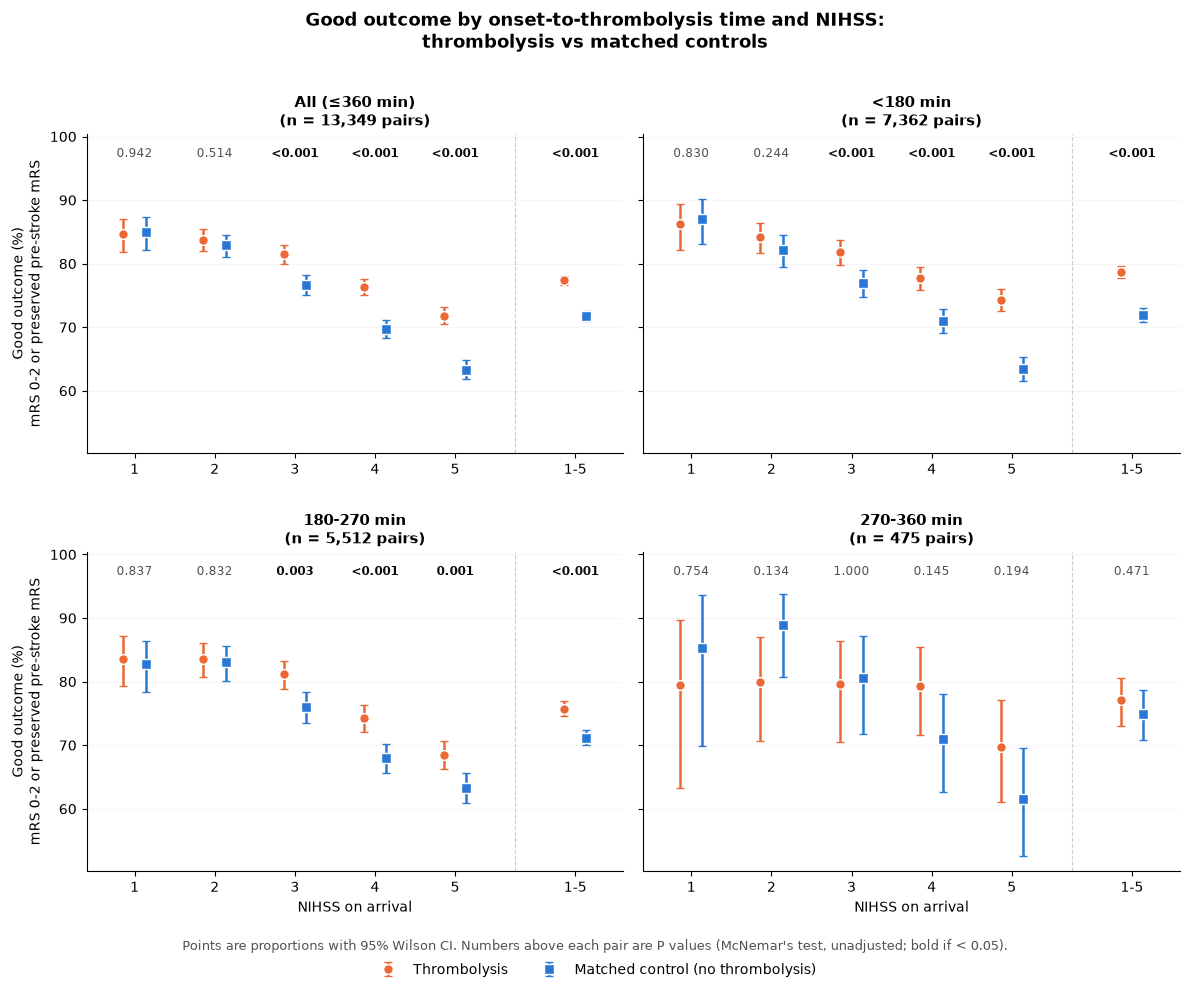

In [9]:
C_TREATED, C_CONTROL = "#eb6834", "#2a78d6"
INK, MUTED = "#0b0b0b", "#52514e"
OFFSET = 0.14

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True)

# Shared y-range across panels, with headroom for P values
y_low = 100 * np.nanmin(results_df[["treated_ci_lower", "untreated_ci_lower"]].to_numpy())
y_high = 100 * np.nanmax(results_df[["treated_ci_upper", "untreated_ci_upper"]].to_numpy())
y_span = y_high - y_low
y_text = y_high + 0.06 * y_span

x = np.arange(len(nihss_order), dtype=float)
x[-1] += 0.5  # gap before the pooled NIHSS 1-5 result

for ax, group_label in zip(axes.flat, group_order):
    df = results_df[results_df["treatment_group"] == group_label].set_index("nihss").reindex(nihss_order)

    for suffix, offset, colour, marker, label in [
        ("treated", -OFFSET, C_TREATED, "o", "Thrombolysis"),
        ("untreated", OFFSET, C_CONTROL, "s", "Matched control (no thrombolysis)"),
    ]:
        mean = 100 * df[f"{suffix}_good_outcome"].to_numpy(dtype=float)
        lower = 100 * df[f"{suffix}_ci_lower"].to_numpy(dtype=float)
        upper = 100 * df[f"{suffix}_ci_upper"].to_numpy(dtype=float)
        ax.errorbar(x + offset, mean, yerr=[mean - lower, upper - mean],
                    fmt=marker, color=colour, ecolor=colour, markersize=7,
                    markeredgecolor="white", markeredgewidth=1,
                    capsize=3, elinewidth=1.8, label=label, zorder=3)

    for xi, p_value in zip(x, df["p_value_mcnemar"]):
        if pd.isna(p_value):
            continue
        ax.text(xi, y_text, fmt_p(p_value), ha="center", va="bottom", fontsize=8.5,
                fontweight="bold" if p_value < 0.05 else "normal",
                color=INK if p_value < 0.05 else MUTED)

    # Divider between individual NIHSS scores and pooled result
    ax.axvline((x[-2] + x[-1]) / 2, color="0.8", lw=0.8, linestyle="--", zorder=0)

    n_pairs = df.loc["1-5", "matched_n"]
    ax.set_title(f"{group_label}\n(n = {int(n_pairs):,} pairs)", fontweight="bold", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(nihss_order)
    ax.set_xlim(x[0] - 0.6, x[-1] + 0.6)
    ax.grid(axis="y", alpha=0.3, linestyle=":")
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0, 0].set_ylim(y_low - 0.06 * y_span, y_text + 0.10 * y_span)
for ax in axes[:, 0]:
    ax.set_ylabel(f"Good outcome (%)\nmRS 0-{MRS_TARGET} or preserved pre-stroke mRS")
for ax in axes[-1, :]:
    ax.set_xlabel("NIHSS on arrival")

handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Good outcome by onset-to-thrombolysis time and NIHSS:\nthrombolysis vs matched controls",
             fontweight="bold", fontsize=13)
fig.text(0.5, 0.04, "Points are proportions with 95% Wilson CI. Numbers above each pair are P values "
         "(McNemar's test, unadjusted; bold if < 0.05).", ha="center", fontsize=9, color=MUTED)
fig.tight_layout(rect=(0, 0.06, 1, 0.97), h_pad=2.5)
fig.savefig(f"{OUTPUT_DIR}/{prefix}.png", dpi=300)
plt.show()

**What this shows:**

* **Control outcomes** (blue) fall steeply from NIHSS 1 to 5.
* **Treated outcomes** (orange) fall less steeply, so the gap between them opens from NIHSS 3 onwards.
* **The gap is widest** in the < 180 min panel.
* **In the 270–360 min panel**, the points for each NIHSS score have wide CIs that overlap, reflecting the small numbers.

## Balance of patient characteristics after matching

Matching features should be identical within pairs. Comorbidities (heart failure, hypertension, diabetes) are **not** matched, so this checks how similar matched treated and control patients are on them. Balance is measured with the standardised mean difference, $SMD = (\bar{x}_T - \bar{x}_C) / \sqrt{(s_T^2 + s_C^2)/2}$; an absolute SMD below 0.1 is usually taken as good balance.

In [10]:
def smd(treated, untreated):
    treated, untreated = pd.to_numeric(treated, errors="coerce"), pd.to_numeric(untreated, errors="coerce")
    pooled_sd = np.sqrt((treated.std() ** 2 + untreated.std() ** 2) / 2)
    return (treated.mean() - untreated.mean()) / pooled_sd if pooled_sd > 0 else 0.0


matched_treated = pd.concat([s["treated"] for s in matched_samples.values()], ignore_index=True)
matched_untreated = pd.concat([s["untreated"] for s in matched_samples.values()], ignore_index=True)

balance = {}
for nihss_label in nihss_order:
    keep = (np.ones(len(matched_treated), dtype=bool) if nihss_label == "1-5"
            else (matched_treated["stroke_severity"] == int(nihss_label)).to_numpy())
    balance[f"NIHSS {nihss_label}"] = {
        feature: smd(matched_treated.loc[keep, feature], matched_untreated.loc[keep, feature])
        for feature in BASELINE_FEATURES
    }
balance_table = pd.DataFrame(balance).round(3)
balance_table.to_csv(f"{OUTPUT_DIR}/{prefix}_balance_smd.csv")
balance_table

,NIHSS 1,NIHSS 2,NIHSS 3,NIHSS 4,NIHSS 5,NIHSS 1-5
prior_disability,0.000,0.000,0.000,0.000,0.000,0.000
stroke_severity,0.000,0.000,0.000,0.000,0.000,0.000
age,0.000,0.000,0.000,0.000,0.000,0.000
afib_anticoagulant,0.000,0.000,0.000,0.000,0.000,0.000
any_afib_diagnosis,0.000,0.000,0.000,0.000,0.000,0.000
congestive_heart_failure,-0.037,-0.018,-0.030,0.006,-0.001,-0.009
hypertension,-0.028,-0.060,-0.033,-0.062,-0.037,-0.046
diabetes,-0.074,-0.104,-0.088,-0.103,-0.029,-0.075


**What this shows:**

* **Matching features** are perfectly balanced (SMD 0), because NIHSS is matched exactly here.
* **Unmatched comorbidities** are well balanced:
  * heart failure: SMD close to 0
  * hypertension: −0.03 to −0.06
  * diabetes: −0.03 to −0.10

  Thrombolysed patients are slightly less likely to have diabetes than their matched controls (pooled SMD −0.075), just reaching −0.1 at NIHSS 2 and 4. This small imbalance would slightly favour thrombolysis. The sensitivity analysis that also matches on comorbidities shows it makes little difference.

## Sensitivity analyses

These test whether the main results (the difference in good outcome for all thrombolysed patients, by NIHSS) depend on choices made in the analysis. Each analysis changes **one** choice.

| Category | Analysis | Why |
|---|---|---|
| Inference | Cluster-robust CI | Pairs sharing a control are not independent. Standard errors are clustered on the control patient. |
| Matching | Controls used once only / up to 5 times / unlimited | Tests the choice of `MAX_CONTROL_USES` (k = 3). |
| Matching | Reverse matching order of time windows | The reuse limit is shared across windows, so the matching order could matter. |
| Matching | Also match on heart failure, hypertension, diabetes | Tests confounding by comorbidities that are not matched. |
| Cohort | Arrival within 180 min | Patients arriving later in the 4-hour window have less time to be treated, so untreated late arrivals may differ from treated ones. |
| Cohort | All teams / teams with at least 20 thrombolyses | Tests the team thrombolysis-volume restriction (at least 10). |
| Outcome | mRS 0–2 only; mRS 0–1 only; mRS 0–1 or no worse than pre-stroke | mRS 0–1 (excellent outcome) is the usual outcome in trials of mild stroke. |
| Matching | 20 random seeds | The control is picked at random, so the estimate varies with the seed. |
| Unmeasured confounding | E-values | How strong an unmeasured confounder would have to be to explain away the result. |

All rows are for **all thrombolysed patients (≤ 360 min)**, by NIHSS.

In [11]:
def pair_outcomes(pairs, mrs_target=None, allow_no_worse_than_prior=True):
    # Treated and control good outcomes for each pair; default = primary outcome
    if mrs_target is None:
        return pairs["treated_outcome"].to_numpy(), pairs["untreated_outcome"].to_numpy()
    out = []
    for arm in ("treated", "untreated"):
        good = pairs[f"{arm}_mrs"] <= mrs_target
        if allow_no_worse_than_prior:
            good = good | (pairs[f"{arm}_mrs"] <= pairs[f"{arm}_prior_mrs"])
        out.append(good.astype(int).to_numpy())
    return out[0], out[1]


def effects_by_nihss(pairs, treated_all, analysis, category, outcome_kwargs=None, clustered=False):
    # Paired difference in good outcome (treated - control) for each NIHSS and pooled 1-5.
    # clustered=True: CI from regressing pair differences on a constant, SEs clustered on control.
    rows = []
    for nihss_label in nihss_order:
        p = select(pairs, nihss_label)
        n_total = len(select(treated_all, nihss_label))
        treated, untreated = pair_outcomes(p, **(outcome_kwargs or {}))
        if clustered:
            d = treated.astype(float) - untreated
            fit = sm.OLS(d, np.ones(len(d))).fit(cov_type="cluster", cov_kwds={"groups": p["control_id"].to_numpy()})
            diff, (lower, upper), p_value = fit.params[0], fit.conf_int()[0], fit.pvalues[0]
        else:
            diff, lower, upper = paired_difference_ci(treated, untreated)
            p_value = mcnemar_p(treated, untreated)[0]
        rows.append({
            "category": category, "analysis": analysis, "nihss": nihss_label,
            "matched_n": len(p), "percent_matched": 100 * len(p) / n_total if n_total else np.nan,
            "treated_good_outcome": treated.mean(), "control_good_outcome": untreated.mean(),
            "difference": diff, "ci_lower": lower, "ci_upper": upper, "p_value": p_value,
        })
    return pd.DataFrame(rows)


def run_scenario(analysis, category, cohort_kwargs=None, match_kwargs=None):
    # Rebuild cohort (if needed), re-match and summarise
    cohort = build_cohort(raw_data, **cohort_kwargs) if cohort_kwargs else data
    matched, _, _ = match_patients(cohort, **(match_kwargs or {}))
    return effects_by_nihss(make_pairs(matched), cohort[cohort["treatment_group"] != CONTROL_GROUP],
                            analysis, category)

In [12]:
reverse_order = sorted((g for g in data["treatment_group"].unique() if g != CONTROL_GROUP), reverse=True)

# (analysis, category, cohort settings, matching settings)
SCENARIOS = [
    ("Controls used once only (k = 1)", "Matching", None, {"max_control_uses": 1}),
    ("Controls used up to 5 times (k = 5)", "Matching", None, {"max_control_uses": 5}),
    ("Unlimited control reuse", "Matching", None, {"max_control_uses": None}),
    ("Reverse matching order of time windows", "Matching", None, {"group_order": reverse_order}),
    ("Also match on CHF, hypertension, diabetes", "Matching", None,
     {"matching_features": MATCHING_FEATURES + COMORBIDITIES}),
    ("Arrival within 180 min", "Cohort", {"max_arrival": 180}, None),
    ("All teams (no thrombolysis-volume limit)", "Cohort", {"min_team_thrombolysis": 0}, None),
    ("Teams with at least 20 thrombolyses", "Cohort", {"min_team_thrombolysis": 20}, None),
]

OUTCOME_SCENARIOS = [
    ("Outcome: mRS 0-2 only", {"mrs_target": 2, "allow_no_worse_than_prior": False}),
    ("Outcome: mRS 0-1 only", {"mrs_target": 1, "allow_no_worse_than_prior": False}),
    ("Outcome: mRS 0-1 or no worse than pre-stroke", {"mrs_target": 1}),
]

sensitivity_results = [
    effects_by_nihss(pairs, treated_all, "Primary", "Primary"),
    effects_by_nihss(pairs, treated_all, "Cluster-robust CI (clustered on control)", "Inference", clustered=True),
]
for analysis, category, cohort_kwargs, match_kwargs in SCENARIOS:
    print(f"Running: {analysis}")
    sensitivity_results.append(run_scenario(analysis, category, cohort_kwargs, match_kwargs))
for analysis, outcome_kwargs in OUTCOME_SCENARIOS:
    sensitivity_results.append(
        effects_by_nihss(pairs, treated_all, analysis, "Outcome definition", outcome_kwargs=outcome_kwargs))

sensitivity_df = pd.concat(sensitivity_results, ignore_index=True)
sensitivity_df["difference_publish_pp"] = [
    fmt_pct(m, l, u) for m, l, u in zip(sensitivity_df["difference"], sensitivity_df["ci_lower"], sensitivity_df["ci_upper"])]
sensitivity_df.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)
analysis_order = list(dict.fromkeys(sensitivity_df["analysis"]))


def sensitivity_pivot(values):
    # Rows = analysis, columns = NIHSS
    table = sensitivity_df.pivot(index="analysis", columns="nihss", values=values).reindex(
        index=analysis_order, columns=nihss_order)
    table.columns = [f"NIHSS {c}" for c in table.columns]
    return table


# Difference in good outcome, percentage points (95% CI)
sensitivity_table = sensitivity_pivot("difference_publish_pp")
sensitivity_table.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_table.csv")
sensitivity_table

Running: Controls used once only (k = 1)
Running: Controls used up to 5 times (k = 5)
Running: Unlimited control reuse
Running: Reverse matching order of time windows
Running: Also match on CHF, hypertension, diabetes
Running: Arrival within 180 min
Running: All teams (no thrombolysis-volume limit)
Running: Teams with at least 20 thrombolyses


,NIHSS 1,NIHSS 2,NIHSS 3,NIHSS 4,NIHSS 5,NIHSS 1-5
analysis,,,,,,
Primary,"-0.3 (-4.0, 3.5)","0.9 (-1.6, 3.3)","4.8 (2.7, 6.9)","6.6 (4.7, 8.5)","8.5 (6.6, 10.5)","5.7 (4.7, 6.7)"
Cluster-robust CI (clustered on control),"-0.3 (-4.1, 3.5)","0.9 (-1.7, 3.4)","4.8 (2.5, 7.1)","6.6 (4.3, 8.9)","8.5 (6.1, 11.0)","5.7 (4.5, 6.9)"
Controls used once only (k = 1),"-0.1 (-3.8, 3.5)","0.2 (-2.1, 2.6)","5.0 (2.9, 7.1)","6.5 (4.5, 8.5)","6.5 (4.3, 8.8)","4.9 (3.8, 5.9)"
Controls used up to 5 times (k = 5),"-0.4 (-4.2, 3.3)","1.8 (-0.7, 4.2)","4.8 (2.7, 6.9)","6.8 (4.9, 8.7)","7.4 (5.5, 9.3)","5.5 (4.5, 6.5)"
Unlimited control reuse,"-0.4 (-4.2, 3.3)","1.8 (-0.7, 4.2)","4.8 (2.7, 6.9)","6.8 (4.9, 8.8)","8.1 (6.2, 10.0)","5.8 (4.8, 6.8)"
Reverse matching order of time windows,"-0.4 (-4.2, 3.3)","1.1 (-1.3, 3.6)","5.7 (3.6, 7.8)","6.2 (4.3, 8.1)","7.4 (5.5, 9.3)","5.5 (4.5, 6.5)"
"Also match on CHF, hypertension, diabetes","-1.4 (-5.0, 2.2)","0.9 (-1.5, 3.4)","5.7 (3.6, 7.9)","6.6 (4.7, 8.5)","7.3 (5.4, 9.3)","5.5 (4.4, 6.5)"
Arrival within 180 min,"-0.8 (-4.6, 3.1)","0.8 (-1.8, 3.5)","4.7 (2.5, 7.0)","5.2 (3.2, 7.2)","8.3 (6.3, 10.4)","5.2 (4.1, 6.3)"
All teams (no thrombolysis-volume limit),"-1.2 (-4.9, 2.5)","1.4 (-1.0, 3.8)","5.5 (3.4, 7.6)","5.9 (4.0, 7.8)","7.3 (5.3, 9.2)","5.3 (4.3, 6.3)"


In [13]:
# Percentage of treated patients matched in each analysis
sensitivity_pivot("percent_matched").round(1)

,NIHSS 1,NIHSS 2,NIHSS 3,NIHSS 4,NIHSS 5,NIHSS 1-5
analysis,,,,,,
Primary,100.0,99.9,99.9,99.4,100.0,99.8
Cluster-robust CI (clustered on control),100.0,99.9,99.9,99.4,100.0,99.8
Controls used once only (k = 1),100.0,99.8,99.7,92.6,74.5,89.8
Controls used up to 5 times (k = 5),100.0,99.9,99.9,99.7,100.0,99.9
Unlimited control reuse,100.0,99.9,99.9,99.8,100.0,99.9
Reverse matching order of time windows,100.0,99.9,99.9,99.4,100.0,99.8
"Also match on CHF, hypertension, diabetes",99.2,98.9,98.7,97.7,96.9,97.9
Arrival within 180 min,100.0,99.9,99.6,99.0,99.9,99.6
All teams (no thrombolysis-volume limit),100.0,99.9,99.9,99.4,100.0,99.8


**What this shows:**

* **Cluster-robust CIs** are only slightly wider than the paired CIs (pooled NIHSS 1–5: 4.5 to 6.9 vs 4.7 to 6.7), so reuse of controls has little effect on precision.
* **Control reuse:**
  * With each control used only once, not enough controls are left at higher NIHSS. Only 92.6% of NIHSS 4 and 74.5% of NIHSS 5 patients are matched, and the NIHSS 5 estimate falls to +6.5 points, for a different, partly matched group.
  * Allowing 5 uses or unlimited reuse gives results close to the primary analysis.
* **Reversing the matching order** of time windows moves individual NIHSS estimates by up to about 1 point (pooled +5.5 vs +5.7). The order matters a little, but not to the conclusions.
* **Also matching on comorbidities** changes little: pooled +5.5, NIHSS 3 +5.7, NIHSS 5 +7.3.
* **Arrival within 180 min:** results are similar (pooled +5.2), so the result is not driven by untreated patients who arrived too late to be treated.
* **Team thrombolysis volume:** pooled estimates stay between +5.3 and +5.6 points. With teams giving at least 20 thrombolyses, NIHSS 2 shows +2.7 (0.3 to 5.1). This is the only analysis where its CI excludes zero, so it is probably chance.
* **Outcome definition:**
  * mRS 0–2 alone gives almost the same results as the primary outcome.
  * With the stricter **mRS 0–1 (excellent outcome)**, the benefit is a little larger: pooled +6.5 points, and NIHSS 4 +8.8.
  * At NIHSS 2 there is a hint of benefit on excellent outcome (+2.6, CI −0.5 to 5.7); NIHSS 1 is still about zero.

**Overall:** the pattern is consistent across all analyses. There is no effect at NIHSS 1, a small and uncertain effect at NIHSS 2, and a clear benefit at NIHSS 3–5 (CIs exclude zero in every analysis).

### Forest plot

One panel per NIHSS score (and pooled 1–5). Points are the difference in good outcome (treated minus matched control, percentage points) with 95% CI. The dashed line is the primary estimate; the grey line is no difference.

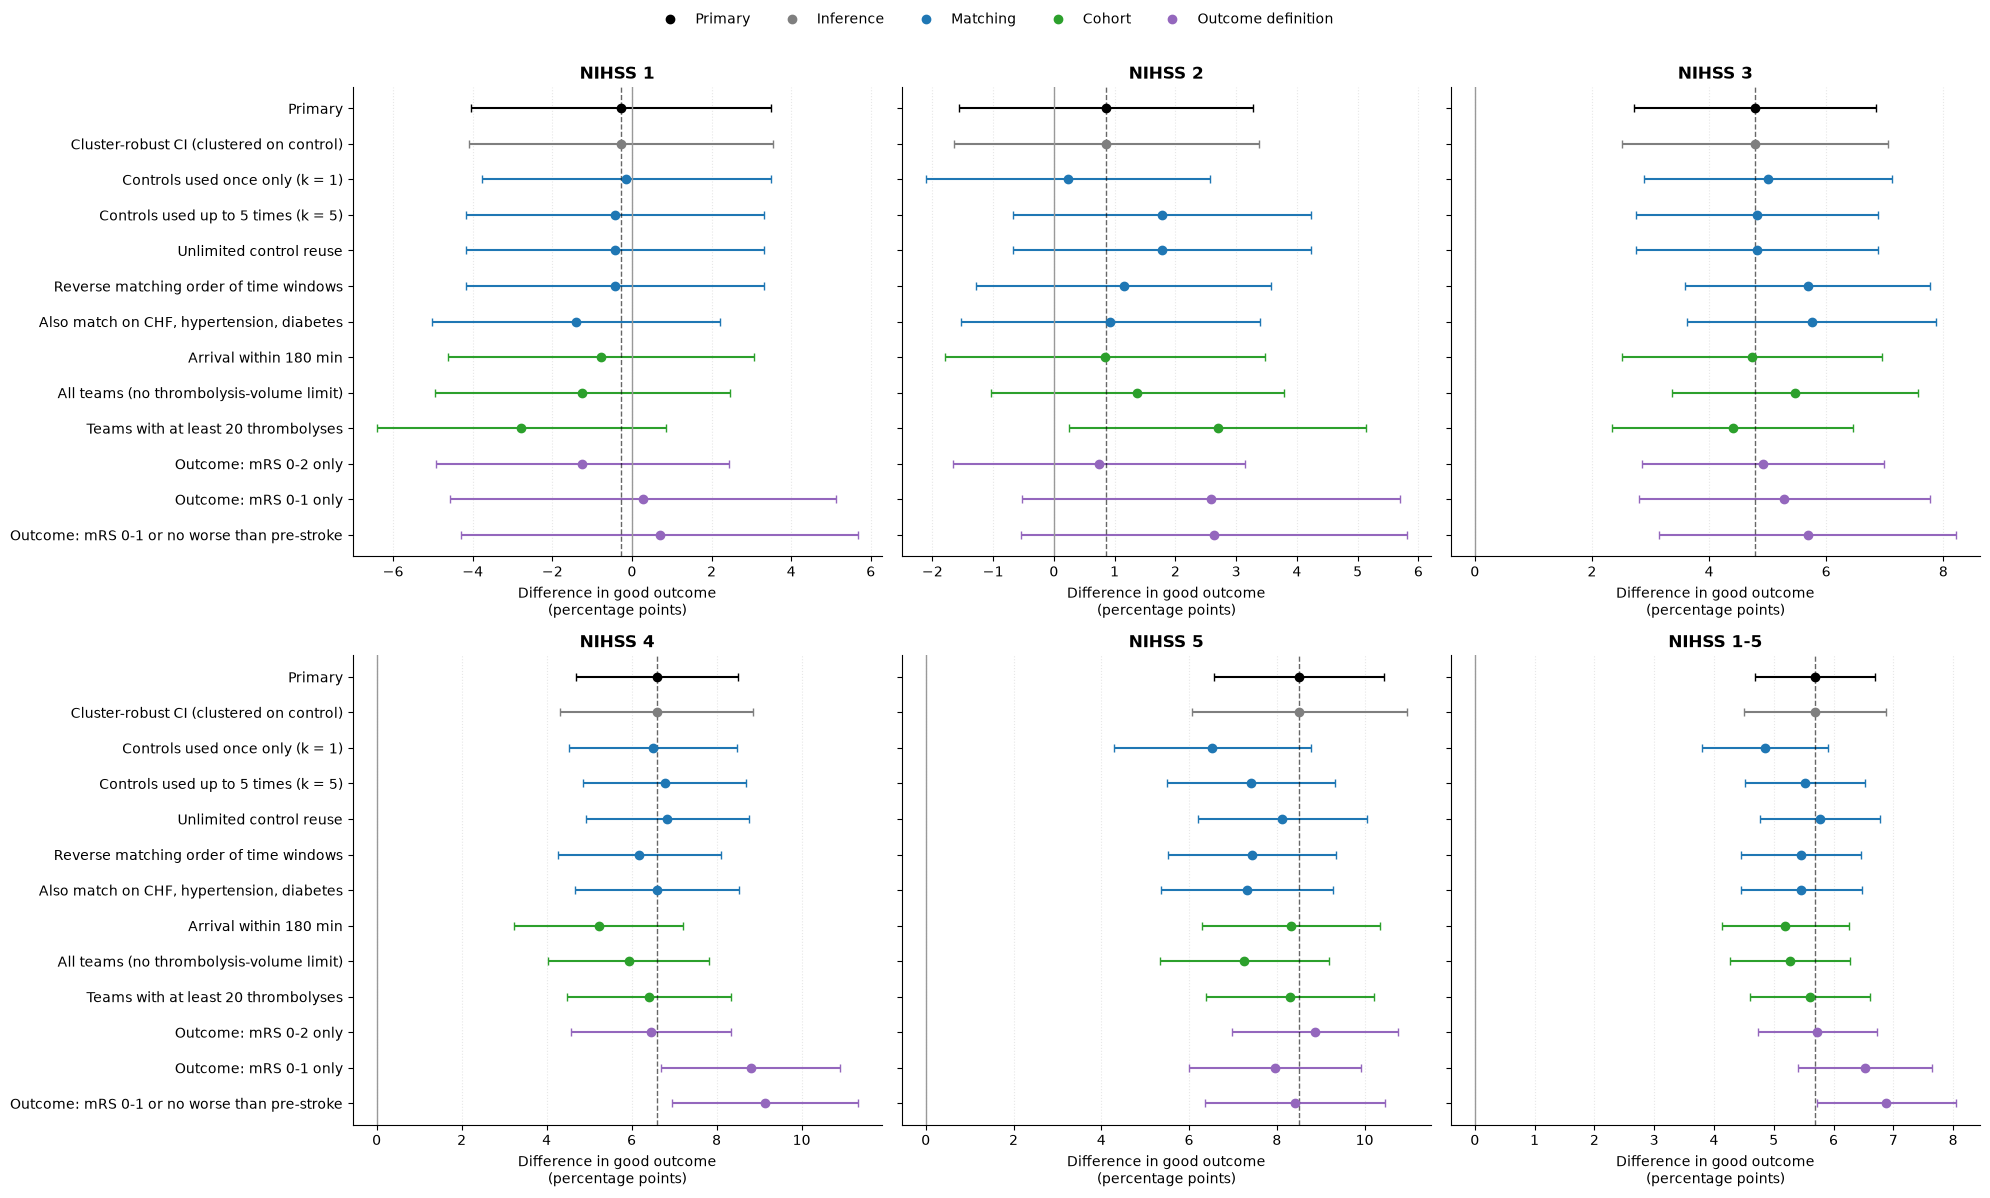

In [14]:
category_colours = {
    "Primary": "black",
    "Inference": "#7f7f7f",
    "Matching": "#1f77b4",
    "Cohort": "#2ca02c",
    "Outcome definition": "#9467bd",
}
fig, axes = plt.subplots(2, 3, figsize=(20, 12), sharey=True)
y_pos = {a: i for i, a in enumerate(analysis_order[::-1])}  # primary at the top

for ax, nihss_label in zip(axes.flat, nihss_order):
    df = sensitivity_df[sensitivity_df["nihss"] == nihss_label]
    for _, r in df.iterrows():
        colour = category_colours[r["category"]]
        ax.errorbar(100 * r["difference"], y_pos[r["analysis"]],
                    xerr=[[100 * (r["difference"] - r["ci_lower"])], [100 * (r["ci_upper"] - r["difference"])]],
                    fmt="o", color=colour, ecolor=colour, capsize=3, markersize=6)
    primary = df.loc[df["analysis"] == "Primary", "difference"].iloc[0]
    ax.axvline(100 * primary, color="black", linestyle="--", lw=1, alpha=0.6)
    ax.axvline(0, color="0.6", lw=1)
    ax.set_title(f"NIHSS {nihss_label}", fontweight="bold")
    ax.set_xlabel("Difference in good outcome\n(percentage points)")
    ax.grid(axis="x", alpha=0.3, linestyle=":")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0, 0].set_yticks(list(y_pos.values()))
axes[0, 0].set_yticklabels(list(y_pos.keys()))
for ax in axes[:, 0]:
    ax.tick_params(labelleft=True)

handles = [plt.Line2D([], [], marker="o", color=c, linestyle="", label=k) for k, c in category_colours.items()]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(f"{OUTPUT_DIR}/{prefix}_sensitivity.png", dpi=300)
plt.show()

### Variation from the random choice of control

Repeating the matching with 20 different random seeds shows how much the estimates move because of the random choice of control alone. Seeds are spaced widely apart so that runs do not share random draws.

In [15]:
N_SEEDS = 20
seed_df = pd.concat(
    [run_scenario(f"Seed {i}", "Seed", match_kwargs={"base_seed": 1_000_003 * i}) for i in range(1, N_SEEDS + 1)],
    ignore_index=True)
seed_df.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_seeds.csv", index=False)

primary_effects = sensitivity_df[sensitivity_df["analysis"] == "Primary"].set_index("nihss")
seed_summary = (
    seed_df.groupby("nihss")["difference"]
    .agg(median="median", minimum="min", maximum="max")
    .mul(100).reindex(nihss_order).round(1)
)
seed_summary["primary"] = primary_effects["difference"].mul(100).round(1)
seed_summary["n_seeds_ci_excluding_zero"] = (
    seed_df.assign(excludes_zero=(seed_df["ci_lower"] > 0) | (seed_df["ci_upper"] < 0))
    .groupby("nihss")["excludes_zero"].sum()
)
seed_summary  # differences in percentage points

,median,minimum,maximum,primary,n_seeds_ci_excluding_zero
nihss,,,,,
1,-1.8,-2.8,0.8,-0.3,0
2,1.2,-0.5,3.4,0.9,3
3,5.2,4.0,6.8,4.8,20
4,6.1,4.9,7.1,6.6,20
5,7.3,6.4,8.9,8.5,20
1-5,5.4,4.9,5.9,5.7,20


**What this shows:**

* **Pooled NIHSS 1–5** is stable: +4.9 to +5.9 points across 20 seeds (median 5.4; primary seed 5.7).
* **Individual NIHSS scores** move more:
  * NIHSS 1: −2.8 to +0.8
  * NIHSS 2: −0.5 to +3.4 (CI excludes zero in only 3 of 20 seeds)
  * NIHSS 3: +4.0 to +6.8
  * NIHSS 4: +4.9 to +7.1
  * NIHSS 5: +6.4 to +8.9
* **The primary seed** gives estimates near the upper end of the range at NIHSS 5 (8.5 vs median 7.3). Reporting the median over seeds, or averaging over several matchings, would give a more representative estimate.
* **NIHSS 3–5:** the CI excludes zero for every seed.

### E-values for unmeasured confounding

The E-value is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with **both** thrombolysis and good outcome (beyond the matched variables) to fully explain away the observed effect. The E-value for the CI uses the confidence limit closest to no effect; a value of 1 means the CI already includes no effect.

VanderWeele TJ, Ding P. Sensitivity analysis in observational research: introducing the E-value. *Ann Intern Med* 2017;167:268–274.

Risk ratios are treated proportion / control proportion with a log-scale 95% CI that ignores the pairing.

In [16]:
def e_value(rr):
    rr = np.asarray(rr, dtype=float)
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))

ev = primary_effects.reindex(nihss_order).reset_index()
p_t, p_c, n = ev["treated_good_outcome"], ev["control_good_outcome"], ev["matched_n"]
ev["risk_ratio"] = p_t / p_c
se_log_rr = np.sqrt((1 - p_t) / (n * p_t) + (1 - p_c) / (n * p_c))
ev["rr_ci_lower"] = np.exp(np.log(ev["risk_ratio"]) - 1.96 * se_log_rr)
ev["rr_ci_upper"] = np.exp(np.log(ev["risk_ratio"]) + 1.96 * se_log_rr)
ev["e_value"] = e_value(ev["risk_ratio"])
closest_limit = np.where(ev["risk_ratio"] >= 1, ev["rr_ci_lower"], ev["rr_ci_upper"])
crosses_null = (ev["rr_ci_lower"] <= 1) & (ev["rr_ci_upper"] >= 1)
ev["e_value_ci"] = np.where(crosses_null, 1.0, e_value(closest_limit))

ev_out = ev[["nihss", "matched_n", "risk_ratio", "rr_ci_lower", "rr_ci_upper", "e_value", "e_value_ci"]]
ev_out.to_csv(f"{OUTPUT_DIR}/{prefix}_e_values.csv", index=False)
ev_out.round(2)

,nihss,matched_n,risk_ratio,rr_ci_lower,rr_ci_upper,e_value,e_value_ci
0,1,722,1.00,0.95,1.04,1.06,1.00
1,2,1745,1.01,0.98,1.04,1.11,1.00
2,3,2781,1.06,1.03,1.09,1.32,1.22
3,4,3929,1.09,1.07,1.12,1.42,1.33
4,5,4172,1.13,1.10,1.17,1.52,1.43
5,1-5,13349,1.08,1.06,1.09,1.37,1.33


**What this shows:**

* **The E-values are modest:**
  * pooled NIHSS 1–5: 1.37 (CI limit 1.33)
  * NIHSS 3: 1.32 (CI limit 1.22)
  * NIHSS 5: 1.52 (CI limit 1.43)
* **Why they are low:** good outcome is common in mild stroke (64–85% of controls), so even a clinically important difference of 5–9 percentage points is a risk ratio of only 1.06–1.13.
* **What that means:** an unmeasured confounder associated with both thrombolysis and good outcome by a risk ratio of about 1.3–1.5 could explain away the result. That is not a strong confounder.
* **Likely candidates** pull in opposite directions:
  * whether deficits are disabling
  * rapidly improving symptoms, a common reason not to treat; these patients usually do well, which would bias *against* thrombolysis
  * frailty not captured by pre-stroke mRS

## Conclusions and limitations

### Conclusions

* **NIHSS 3–5:** in patients with mild ischaemic stroke arriving within 4 hours, thrombolysis is associated with more good outcomes at discharge. The benefit rises with NIHSS (+4.8, +6.6 and +8.5 percentage points at NIHSS 3, 4 and 5) and is largest when treatment is given within 180 minutes.
* **NIHSS 1:** there is no evidence of benefit.
* **NIHSS 2:** any benefit is small. The CIs rule out more than about 3 points for good outcome, or about 6 points for excellent outcome (mRS 0–1).
* **Sensitivity analyses:** the findings are consistent across analyses of matching choices, cohort definition, outcome definition and random seed.

### Limitations

* **Unmeasured confounding.**
  * Not recorded or not matched:
    * whether the deficit is disabling (for example aphasia or hemianopia at a low NIHSS)
    * rapidly improving symptoms
    * imaging findings
    * frailty
  * At low NIHSS, clinicians may thrombolyse mainly patients with disabling deficits, whose outcomes would otherwise be worse. That could hide a real benefit at NIHSS 1–2, or other factors could bias in either direction.
  * The modest E-values mean such confounding does not have to be strong to matter.
* **Outcome at discharge, and a ceiling effect.** Most controls at NIHSS 1–2 already have a good outcome. Discharge mRS may be too coarse to detect small benefits, and 90-day outcomes are not available.
* **Harms are not analysed.** The net benefit of thrombolysis at low NIHSS also depends on symptomatic intracranial haemorrhage, which this notebook does not compare.
* **Multiple comparisons.** There are 24 rows in the main table and 13 analyses in the sensitivity table. P values are unadjusted, and small rows (especially 270–360 min) should not be over-interpreted.
* **Matching choices.**
  * The shared limit on control reuse makes results depend slightly on matching order.
  * The random choice of control moves individual NIHSS estimates by up to about 2–3 points.